# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest**
neural crest) were scored in 02 against the shared **union** control pool and graph-smoothed.
Here we render them as deliverables and evaluate **Gate 2**.

**Gate 2 (non-branching case).** Puram's branching manifold splits Gast and pSom into *distinct
arms* with Crest terminal at the tips. Ji's manifold does **not** branch (02: the only fork is
the cycling compartment; the developmental axis is a single fold-free curve). The correct Gate-2
signature is therefore a **shared developmental gradient with an inverse terminal Crest**: Gast
and pSom overlap in the differentiating body and decline along the trajectory, while neural crest
rises toward the terminus. That pattern is present, so **Gate 2 = GO (non-branching)**; with no
bifurcation the cross-repression test is **Gate 3 = NA**. Gast and pSom *do* show organized
gene-level cross-repression on the hub (r reported below for context) — but per §1 (the Wu 2021
clarification) organized cross-repression with a terminal Crest gradient and no arm-resolution is
the non-branching case, not branching. Deliverable: `signatures.h5ad`,
`{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [ ]:

import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)


### Load the rooted manifold (signatures scored + smoothed in 02)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 10504 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 76/81 genes present
pSom: 88/98 genes present
Crest: 101/104 genes present


### Gate 2 — module geography on the manifold
Non-branching signature test: (i) Gast & pSom spatially overlap (co-localize, not anti-segregate
into two arms); (ii) Crest is their spatial inverse; (iii) along pseudotime Gast/pSom decline while
Crest rises (Crest terminal). For context we also report the gene-level Gast↔pSom cross-repression
on the differentiating hub (the quantity Gate 3 would test if this manifold branched).

In [ ]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
lo = adata.obs['Gast_sm'] >= adata.obs['Gast_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print(f'Gastrulation-high decile mean pseudotime = {tn[lo.values].mean():.2f} (origin if ~0)')
# context: gene-level cross-repression on the low-cycling Gast/pSom hub (Mixed+Diff core)
gast_g = set(pd.read_csv(os.path.join(pth_feat,'GSE162534.csv')).hsapiens)
psom_g = set(pd.read_csv(os.path.join(pth_feat,'GSE229103.csv')).hsapiens)
gx = pd.Series(list(gast_g ^ psom_g)); gx = gx.loc[gx.isin(adata.var_names)]
hub = adata.obs.celltype.isin(['Mixed','Diff']) & (adata.obs.cell_cycle_phase=='Not cycling')
H = adata[hub.values, gx.values]; X = pd.DataFrame(H.X.toarray(), columns=gx); X = X.loc[:,X.nunique(0)>1]
rg = pearsonr(X.values, H.obs['Gast'].values[:,None], axis=0).statistic
rp = pearsonr(X.values, H.obs['pSom'].values[:,None], axis=0).statistic
print(f'context: hub gene-level Gast<->pSom cross-repression r = {np.corrcoef(rg,rp)[0,1]:+.2f} (n={int(hub.sum())}) '
      f'-- organized cross-repression present, but Gast/pSom overlap (no arm resolution) -> non-branching')
print('Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.13
  Crest_sm vs Gast_sm: r = -0.68
  Crest_sm vs pSom_sm: r = -0.67
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.620
  pSom_sm: rho = -0.114
  Crest_sm: rho = +0.269
Neural-crest-high decile mean pseudotime = 0.79 (terminal if ~1)
Gastrulation-high decile mean pseudotime = 0.10 (origin if ~0)
context: hub gene-level Gast<->pSom cross-repression r = -0.53 (n=2810) -- organized cross-repression present, but Gast/pSom overlap (no arm resolution) -> non-branching
Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma. Panels
show the **raw** per-cell module scores (the smoothed fields are used only for geography stats).
Colorbar ticks are data-driven from each score's range.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


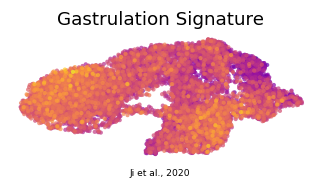

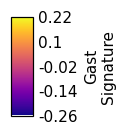

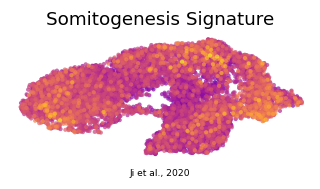

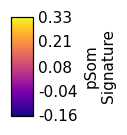

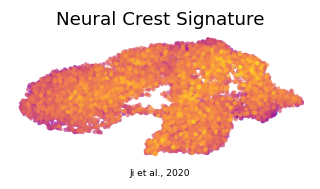

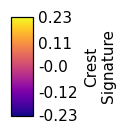

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo_, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo_, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (10504, 21042)
